# Práctica PCD: Asociación

## EDA

In [4]:
import pandas as pd
import numpy as np
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth
import matplotlib.pyplot as plt
import warnings

In [5]:
data = pd.read_csv('bread_basket.xls')
print(data.shape)
data.head(10)

(20507, 5)


,Transaction,Item,date_time,period_day,weekday_weekend
0,1,Bread,30-10-2016 09:58,morning,weekend
1,2,Scandinavian,30-10-2016 10:05,morning,weekend
2,2,Scandinavian,30-10-2016 10:05,morning,weekend
3,3,Hot chocolate,30-10-2016 10:07,morning,weekend
4,3,Jam,30-10-2016 10:07,morning,weekend
5,3,Cookies,30-10-2016 10:07,morning,weekend
6,4,Muffin,30-10-2016 10:08,morning,weekend
7,5,Coffee,30-10-2016 10:13,morning,weekend
8,5,Pastry,30-10-2016 10:13,morning,weekend
9,5,Bread,30-10-2016 10:13,morning,weekend


In [6]:
data.isna().sum()

Transaction        0
Item               0
date_time          0
period_day         0
weekday_weekend    0
dtype: int64

In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20507 entries, 0 to 20506
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Transaction      20507 non-null  int64
 1   Item             20507 non-null  str  
 2   date_time        20507 non-null  str  
 3   period_day       20507 non-null  str  
 4   weekday_weekend  20507 non-null  str  
dtypes: int64(1), str(4)
memory usage: 801.2 KB


In [8]:
data.nunique()

Transaction        9465
Item                 94
date_time          9182
period_day            4
weekday_weekend       2
dtype: int64

In [9]:
data['period_day'].unique()

<StringArray>
['morning', 'afternoon', 'evening', 'night']
Length: 4, dtype: str

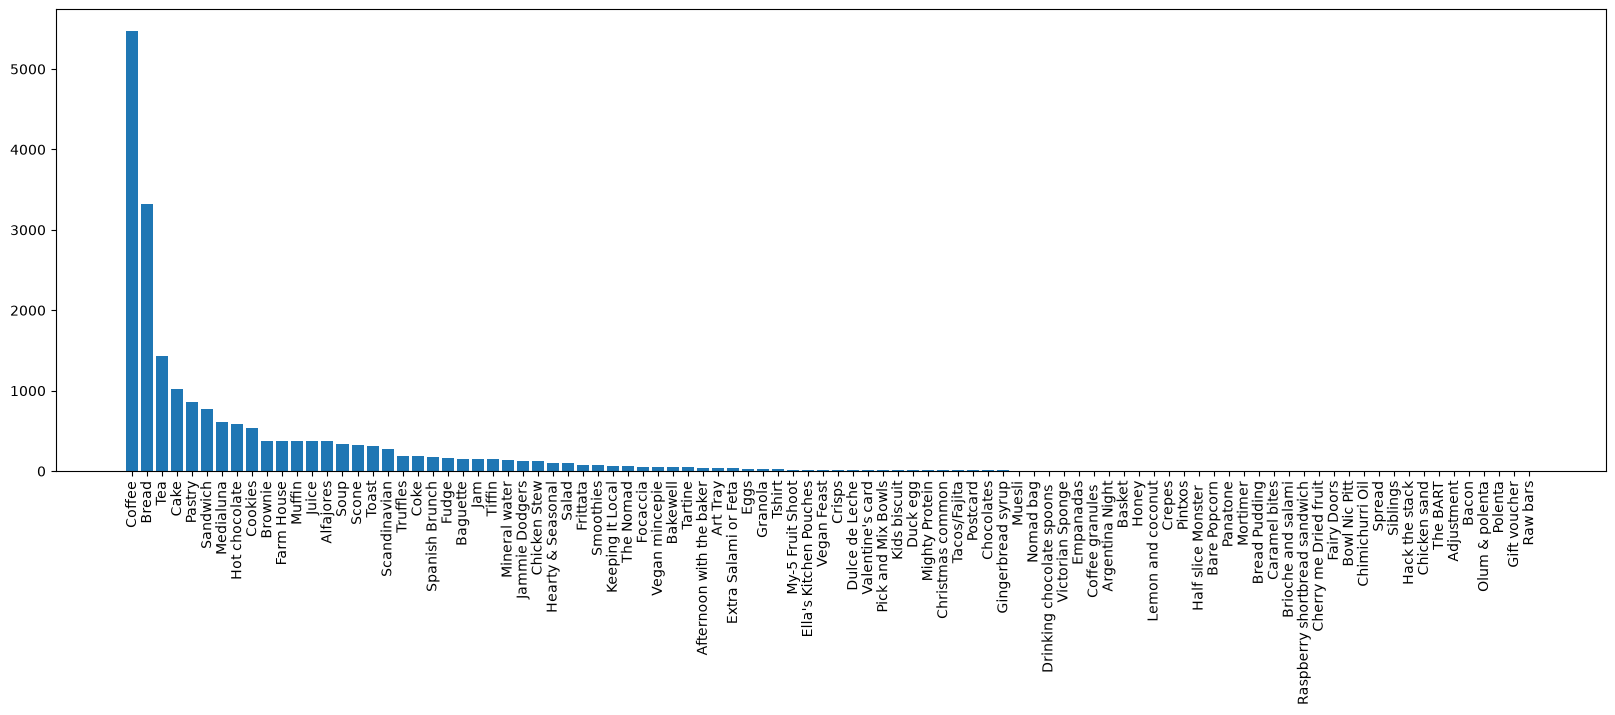

In [10]:
counts = data['Item'].value_counts()
plt.figure(figsize=(20, 6))
plt.bar(counts.index, counts.values)
plt.xticks(rotation=90)
plt.show()



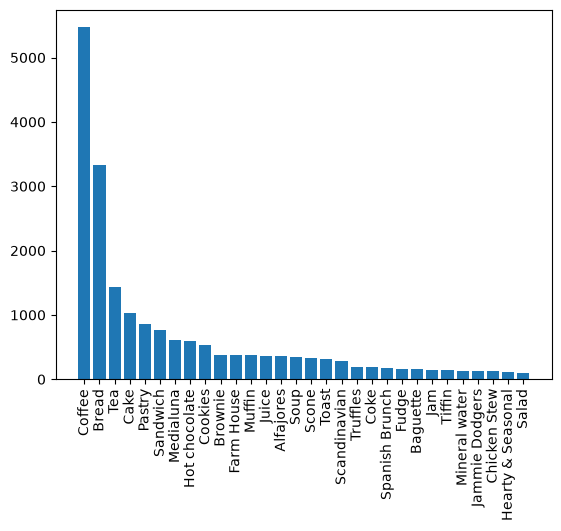

In [11]:
#plt.figure(figsize=(20, 6))
plt.bar(counts.index[:30], counts.values[:30])
plt.xticks(rotation=90)
plt.show()

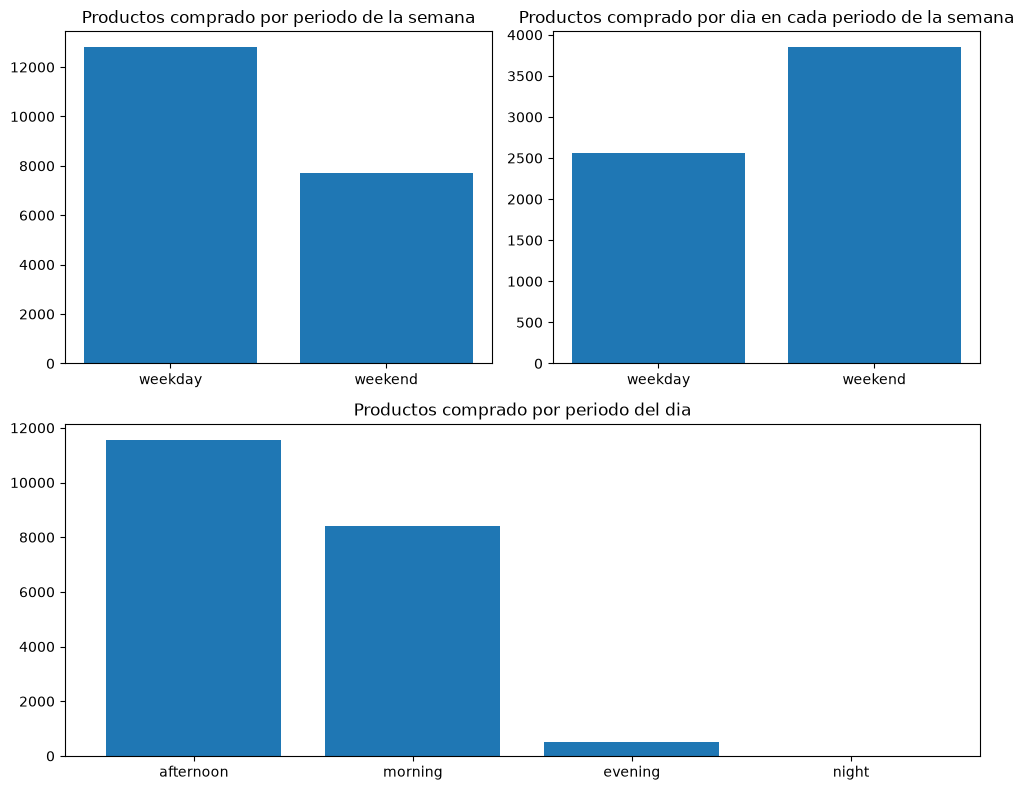

In [12]:
weekend_counts = data['weekday_weekend'].value_counts()
weekend_counts_norm = weekend_counts.astype(float)
weekend_counts_norm['weekend'] = weekend_counts_norm['weekend'] / 2
weekend_counts_norm['weekday'] = weekend_counts_norm['weekday'] / 5

fig, ax = plt.subplot_mosaic(
    [['left', 'right'],
     ['bottom', 'bottom']],
    figsize=(10, 8),
)

ax['left'].bar(weekend_counts.index, weekend_counts.values)
ax['left'].tick_params(axis='x', rotation=0)
ax['left'].set_title('Productos comprado por periodo de la semana')

ax['right'].bar(weekend_counts_norm.index, weekend_counts_norm.values)
ax['right'].tick_params(axis='x', rotation=0)
ax['right'].set_title('Productos comprado por dia en cada periodo de la semana')

period_counts=data['period_day'].value_counts()
ax['bottom'].bar(period_counts.index, period_counts.values)
ax['bottom'].tick_params(axis='x', rotation=0)
ax['bottom'].set_title('Productos comprado por periodo del dia')

plt.tight_layout()
plt.show()

In [13]:
transaction = data.groupby('Transaction').agg(
    Items=('Item', list),
    date_time=('date_time','first'),
    period_day=('period_day','first'),
    weekday_weekend=('weekday_weekend','first')
)

print(transaction.shape)
transaction.head()

(9465, 4)


,Items,date_time,period_day,weekday_weekend
Transaction,,,,
1,[Bread],30-10-2016 09:58,morning,weekend
2,"[Scandinavian, Scandinavian]",30-10-2016 10:05,morning,weekend
3,"[Hot chocolate, Jam, Cookies]",30-10-2016 10:07,morning,weekend
4,[Muffin],30-10-2016 10:08,morning,weekend
5,"[Coffee, Pastry, Bread]",30-10-2016 10:13,morning,weekend


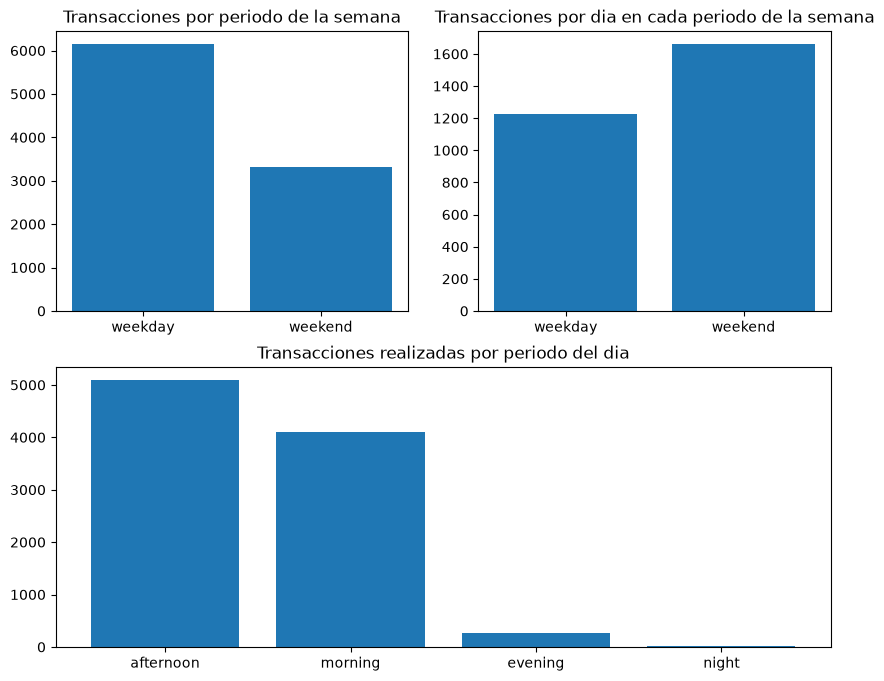

In [14]:
week_transactions = transaction['weekday_weekend'].value_counts()
week_transactions_norm = week_transactions.astype(float)
week_transactions_norm['weekend'] = week_transactions_norm['weekend'] / 2
week_transactions_norm['weekday'] = week_transactions_norm['weekday'] / 5

fig, ax = plt.subplot_mosaic(
    [['left', 'right'],
     ['bottom', 'bottom']],
    figsize=(10, 8),
)

ax['left'].bar(week_transactions.index, week_transactions.values)
ax['left'].tick_params(axis='x')
ax['left'].set_title('Transacciones por periodo de la semana')

ax['right'].bar(week_transactions_norm.index, week_transactions_norm.values)
ax['right'].tick_params(axis='x')
ax['right'].set_title('Transacciones por dia en cada periodo de la semana')


period_counts=transaction['period_day'].value_counts()
ax['bottom'].bar(period_counts.index, period_counts.values)
ax['bottom'].tick_params(axis='x')
ax['bottom'].set_title('Transacciones realizadas por periodo del dia')

plt.show() 

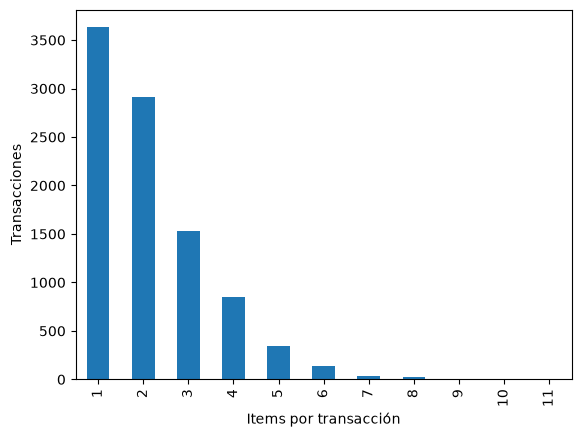

In [15]:

n_items = transaction['Items'].str.len()

n_items.value_counts().sort_index().plot(kind='bar')
plt.xlabel('Items por transacción')
plt.ylabel('Transacciones')
plt.show()

Repeated items within a transaction: 1620
Mean basket size (raw / distinct): 2.17 / 2.00
Single-item transactions: 41.7%


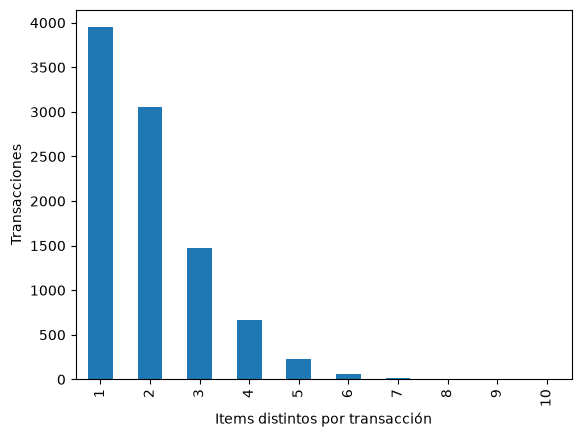

In [16]:
dup_items = data.duplicated(['Transaction', 'Item']).sum()
n_unique_items = transaction['Items'].apply(lambda items: len(set(items)))

print(f'Repeated items within a transaction: {dup_items}')
print(f'Mean basket size (raw / distinct): {n_items.mean():.2f} / {n_unique_items.mean():.2f}')
print(f'Single-item transactions: {(n_unique_items == 1).mean():.1%}')

n_unique_items.value_counts().sort_index().plot(kind='bar')
plt.xlabel('Items distintos por transacción')
plt.ylabel('Transacciones')
plt.show()

**Conclusión:** hay 1620 items repetidos dentro de la misma transacción, que inflan el tamaño de cesta (2.17 → 2.00 items distintos de media). El 41.7 % de las transacciones tienen un solo producto: no aportan co-ocurrencias, pero sí cuentan en el denominador del soporte.

Item
Coffee           0.478
Bread            0.327
Tea              0.143
Cake             0.104
Pastry           0.086
Sandwich         0.072
Medialuna        0.062
Hot chocolate    0.058
Cookies          0.054
Brownie          0.040
Name: count, dtype: float64

Items with support >= 1%: 30 / 94
Items with support >= 2%: 19 / 94
Items with support >= 5%: 9 / 94


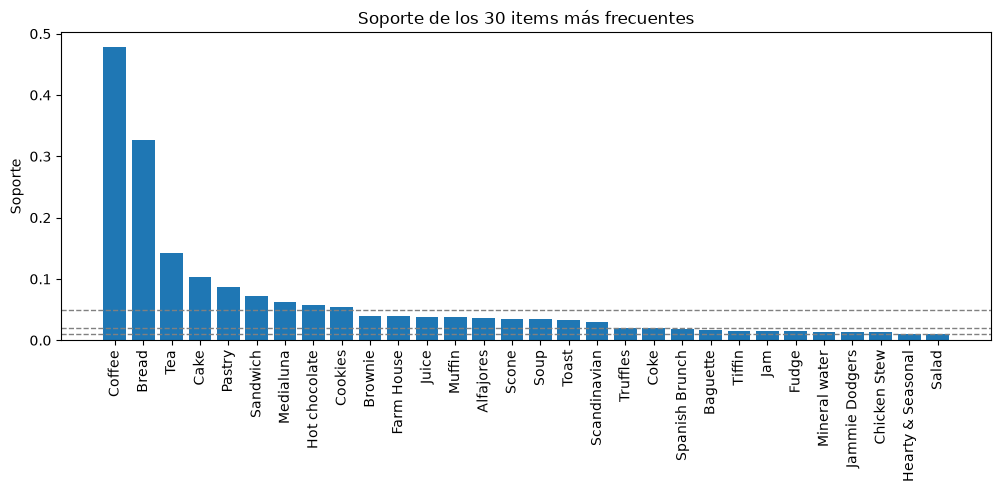

In [17]:

item_support = (
    data.drop_duplicates(['Transaction', 'Item'])['Item'].value_counts()
    / data['Transaction'].nunique()
)
print(item_support.head(10).round(3))
print()
for threshold in [0.01, 0.02, 0.05]:
    print(f'Items with support >= {threshold:.0%}: {(item_support >= threshold).sum()} / {len(item_support)}')

plt.figure(figsize=(12, 4))
plt.bar(item_support.index[:30], item_support.values[:30])
for threshold in [0.01, 0.02, 0.05]:
    plt.axhline(threshold, linestyle='--', linewidth=1, color='gray')
plt.xticks(rotation=90)
plt.ylabel('Soporte')
plt.title('Soporte de los 30 items más frecuentes')
plt.show()

**Conclusión:** Coffee está en casi la mitad de las transacciones (~48 %) y Bread en un tercio (~33 %), así que aparecerán como consecuente en muchas reglas con confidence alta pero poco informativas. Solo 30 de 94 items superan el 1 % de soporte → `min_support` ≈ 0.01–0.02 es un rango razonable.

In [18]:

print(item_support.tail(15).round(4))
print()
print(data['period_day'].value_counts())

Item
Cherry me Dried fruit    0.0003
Fairy Doors              0.0002
Bowl Nic Pitt            0.0002
Chimichurri Oil          0.0002
Spread                   0.0002
Siblings                 0.0002
Hack the stack           0.0002
Chicken sand             0.0001
The BART                 0.0001
Adjustment               0.0001
Bacon                    0.0001
Olum & polenta           0.0001
Polenta                  0.0001
Gift voucher             0.0001
Raw bars                 0.0001
Name: count, dtype: float64

period_day
afternoon    11569
morning       8404
evening        520
night           14
Name: count, dtype: int64


**Conclusión:** la cola de items raros incluye cosas que no son producto (`Adjustment`, `Gift voucher`, `Hack the stack`…). Con un `min_support` razonable desaparecen solas. `night` tiene solo 14 filas, así que no sirve para segmentar reglas por franja horaria.

Date range: 2016-10-30 09:58:00 -> 2017-04-09 15:04:00 (159 days)


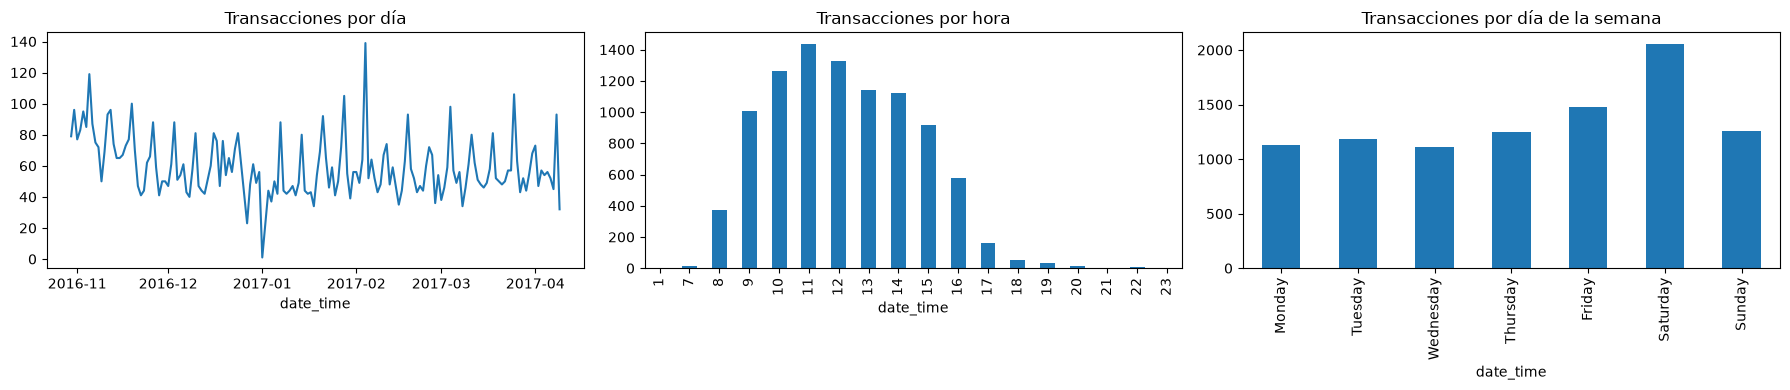

In [19]:
tx_datetime = pd.to_datetime(transaction['date_time'], format='%d-%m-%Y %H:%M')
print(f'Date range: {tx_datetime.min()} -> {tx_datetime.max()} ({tx_datetime.dt.date.nunique()} days)')

fig, ax = plt.subplots(1, 3, figsize=(18, 4))

tx_datetime.dt.date.value_counts().sort_index().plot(ax=ax[0])
ax[0].set_title('Transacciones por día')

tx_datetime.dt.hour.value_counts().sort_index().plot(kind='bar', ax=ax[1])
ax[1].set_title('Transacciones por hora')

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
tx_datetime.dt.day_name().value_counts().reindex(day_order).plot(kind='bar', ax=ax[2])
ax[2].set_title('Transacciones por día de la semana')

plt.tight_layout()
plt.show()

**Conclusión:** 159 días (oct-2016 → abr-2017), ~60 transacciones/día. La actividad se concentra entre las 9h y las 16h y el sábado es el día más fuerte. Hay 46 días de fin de semana frente a 113 entre semana, así que la normalización /2 y /5 es una buena aproximación.

In [20]:
te = TransactionEncoder()
te_ary = te.fit(transaction['Items']).transform(transaction['Items'])
df = pd.DataFrame(te_ary, columns=te.columns_)
df

,Adjustment,Afternoon with the baker,Alfajores,Argentina Night,Art Tray,Bacon,Baguette,Bakewell,Bare Popcorn,Basket,...,The BART,The Nomad,Tiffin,Toast,Truffles,Tshirt,Valentine's card,Vegan Feast,Vegan mincepie,Victorian Sponge
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9460,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9461,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
9462,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9463,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


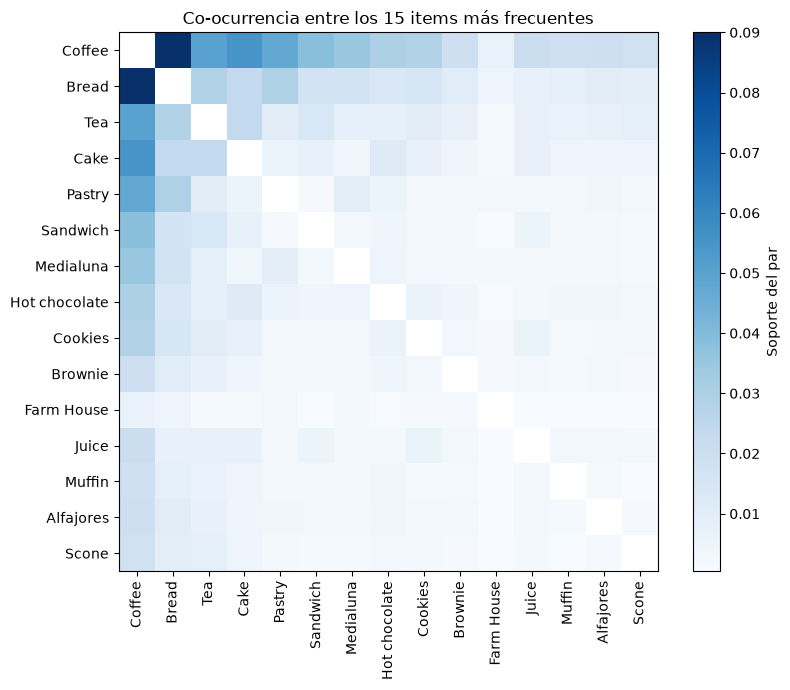

Coffee & Bread -> observed: 0.090 | expected if independent: 0.157 | lift: 0.58


In [21]:

top_items = item_support.index[:15]
top_df = df[top_items].astype(int)
pair_support = (top_df.T @ top_df) / len(df)
pair_support = pair_support.mask(np.eye(len(top_items), dtype=bool))

plt.figure(figsize=(9, 7))
plt.imshow(pair_support, cmap='Blues')
plt.colorbar(label='Soporte del par')
plt.xticks(range(len(top_items)), top_items, rotation=90)
plt.yticks(range(len(top_items)), top_items)
plt.title('Co-ocurrencia entre los 15 items más frecuentes')
plt.show()


observed = pair_support.loc['Coffee', 'Bread']
expected = item_support['Coffee'] * item_support['Bread']
print(f'Coffee & Bread -> observed: {observed:.3f} | expected if independent: {expected:.3f} | lift: {observed / expected:.2f}')

**Conclusión:** los pares más frecuentes casi siempre incluyen Coffee (con Bread, Cake, Tea, Pastry…). Ojo: Coffee+Bread aparece *menos* de lo esperado por azar (lift < 1). Que un par sea frecuente no significa que esté asociado → filtrar las reglas por **lift > 1**.

## Modelos 

In [22]:
import time


def eclat(df, min_support=0.5, use_colnames=True, max_len=None):
    n_transactions = len(df)
    min_count = min_support * n_transactions
    tidsets = [(item, df[item].to_numpy()) for item in df.columns if df[item].sum() >= min_count]
    results = []

    def extend(prefix, prefix_mask, candidates):
        for i, (item, mask) in enumerate(candidates):
            new_mask = mask if prefix_mask is None else prefix_mask & mask
            count = new_mask.sum()
            if count < min_count:
                continue
            itemset = prefix + (item,)
            results.append((count / n_transactions, frozenset(itemset)))
            if max_len is None or len(itemset) < max_len:
                extend(itemset, new_mask, candidates[i + 1:])

    extend((), None, tidsets)
    return pd.DataFrame(results, columns=['support', 'itemsets'])


def time_algorithm(algorithm, df, min_support, n_runs=5):
    times = []
    for _ in range(n_runs):
        start = time.perf_counter()
        result = algorithm(df, min_support=min_support, use_colnames=True)
        times.append(time.perf_counter() - start)
    return np.median(times) * 1000, result


algorithms = {'Apriori': apriori, 'FP-Growth': fpgrowth, 'ECLAT': eclat}

In [23]:
MIN_SUPPORT = 0.01

results, summary = {}, []
for name, algorithm in algorithms.items():
    runtime_ms, result = time_algorithm(algorithm, df, MIN_SUPPORT)
    results[name] = result
    summary.append({
        'algorithm': name,
        'runtime_ms': round(runtime_ms, 2),
        'n_itemsets': len(result),
        **result['itemsets'].apply(len).value_counts().sort_index().add_prefix('size_').to_dict(),
    })

itemset_keys = {name: set(zip(r['itemsets'], r['support'].round(10))) for name, r in results.items()}
print(f"Same itemsets and supports: {itemset_keys['Apriori'] == itemset_keys['FP-Growth'] == itemset_keys['ECLAT']}")
pd.DataFrame(summary).set_index('algorithm')

Same itemsets and supports: True


,runtime_ms,n_itemsets,size_1,size_2,size_3
algorithm,,,,,
Apriori,6.15,61,30,28,3
FP-Growth,18.60,61,30,28,3
ECLAT,6.09,61,30,28,3


**Conclusión:** con `min_support = 0.01` los tres algoritmos encuentran exactamente los mismos 61 itemsets (30 de 1 item, 28 pares y 3 tríos) con el mismo soporte. Solo cambia cómo los buscan.

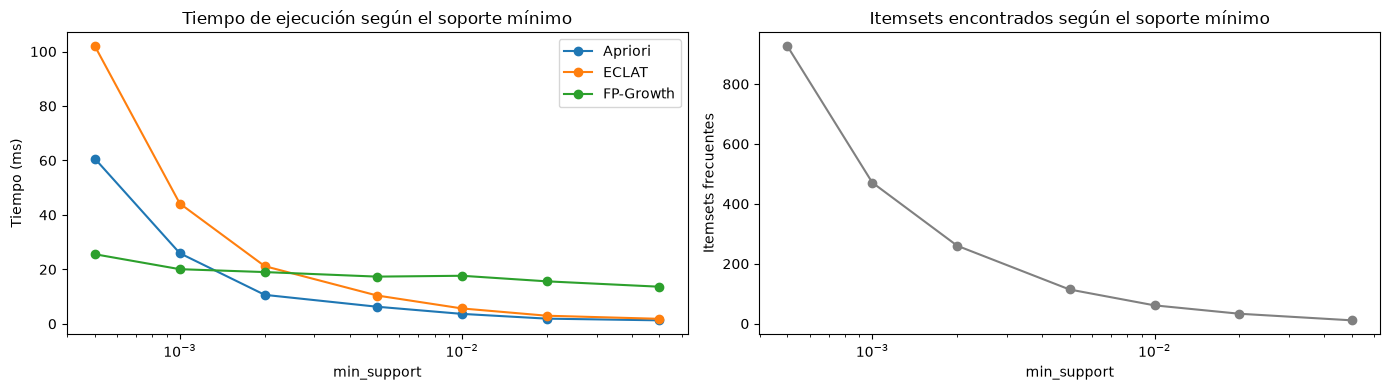

algorithm,Apriori,ECLAT,FP-Growth
min_support,,,
0.0005,60.7,102.0,25.6
0.0010,25.9,44.2,20.1
0.0020,10.6,21.2,19.0
0.0050,6.3,10.4,17.3
0.0100,3.7,5.6,17.7
0.0200,1.9,3.0,15.6
0.0500,1.3,1.8,13.6


In [24]:
support_grid = [0.0005, 0.001, 0.002, 0.005, 0.01, 0.02, 0.05]
benchmark = []
for min_support in support_grid:
    for name, algorithm in algorithms.items():
        runtime_ms, result = time_algorithm(algorithm, df, min_support, n_runs=3)
        benchmark.append({'min_support': min_support, 'algorithm': name,
                          'runtime_ms': runtime_ms, 'n_itemsets': len(result)})
benchmark = pd.DataFrame(benchmark)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for name, group in benchmark.groupby('algorithm'):
    ax[0].plot(group['min_support'], group['runtime_ms'], marker='o', label=name)
ax[0].set_xscale('log')
ax[0].set_xlabel('min_support')
ax[0].set_ylabel('Tiempo (ms)')
ax[0].set_title('Tiempo de ejecución según el soporte mínimo')
ax[0].legend()

n_itemsets = benchmark.drop_duplicates('min_support')
ax[1].plot(n_itemsets['min_support'], n_itemsets['n_itemsets'], marker='o', color='gray')
ax[1].set_xscale('log')
ax[1].set_xlabel('min_support')
ax[1].set_ylabel('Itemsets frecuentes')
ax[1].set_title('Itemsets encontrados según el soporte mínimo')

plt.tight_layout()
plt.show()

benchmark.pivot(index='min_support', columns='algorithm', values='runtime_ms').round(1)

**Conclusión:** con soporte alto Apriori es el más rápido: hay pocos candidatos y la implementación de mlxtend está vectorizada. FP-Growth tiene un coste casi constante (construir el árbol), así que no compensa aquí, pero escala mejor: por debajo del ~0.1 % ya supera a Apriori y a ECLAT, cuando el número de itemsets se dispara.

In [25]:
rules = {
    name: association_rules(result, num_itemsets=len(df), metric='lift', min_threshold=1)
    for name, result in results.items()
}

rule_keys = {name: set(zip(r['antecedents'], r['consequents'])) for name, r in rules.items()}
print(f'Rules with lift > 1: { {name: len(r) for name, r in rules.items()} }')
print(f"Same rules in all algorithms: {rule_keys['Apriori'] == rule_keys['FP-Growth'] == rule_keys['ECLAT']}")

top_rules = rules['Apriori'].sort_values('lift', ascending=False).head(10).copy()
top_rules['antecedents'] = top_rules['antecedents'].apply(lambda s: ', '.join(sorted(s)))
top_rules['consequents'] = top_rules['consequents'].apply(lambda s: ', '.join(sorted(s)))
top_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].round(3)

Rules with lift > 1: {'Apriori': 42, 'FP-Growth': 42, 'ECLAT': 42}
Same rules in all algorithms: True


,antecedents,consequents,support,confidence,lift
38,"Coffee, Tea",Cake,0.010,0.201,1.938
41,Cake,"Coffee, Tea",0.010,0.097,1.938
8,Hot chocolate,Cake,0.011,0.196,1.884
9,Cake,Hot chocolate,0.011,0.110,1.884
11,Cake,Tea,0.024,0.229,1.605
10,Tea,Cake,0.024,0.167,1.605
31,Toast,Coffee,0.024,0.704,1.472
30,Coffee,Toast,0.024,0.049,1.472
36,"Bread, Coffee",Pastry,0.011,0.124,1.445
37,Pastry,"Bread, Coffee",0.011,0.130,1.445


**Conclusión:** con lift > 1 salen 42 reglas, idénticas en los tres algoritmos. Las más fuertes combinan bebida + dulce (Coffee+Tea → Cake, Hot chocolate → Cake, Tea → Cake). La más útil es Toast → Coffee, con un 70 % de confianza.

| | Apriori | FP-Growth | ECLAT |
|---|---|---|---|
| Formato | Horizontal (transacción → items) | Árbol comprimido (FP-tree) | Vertical (item → transacciones) |
| Búsqueda | En anchura: genera candidatos de tamaño k+1 y recorre los datos | Sin candidatos: crece patrones sobre el árbol | En profundidad: intersección de tidsets |
| Fuerte en | Soporte alto, pocos itemsets | Soporte bajo, muchos itemsets | Datos dispersos, itemsets medianos |
| Débil en | Explosión de candidatos con soporte bajo | Coste fijo de construir el árbol | Memoria de tidsets si hay muchas transacciones |

Con soporte 1 % los tres algoritmos devuelven exactamente los mismos itemsets y reglas, así que **la elección es solo de eficiencia**, no de resultado. En este dataset (9.465 transacciones, 94 items) cualquiera sirve; FP-Growth sería la opción a escalar si bajamos el soporte o crece el volumen.